# Customer Support Analytics Dashboard
**Tools:** SQL (SQLite), Python (Pandas, Matplotlib), Tableau

**Goal:** Understand how fast a support team responds and resolves tickets, find the busiest days and hours, and turn the findings into recommendations, then prepare data for an interactive Tableau dashboard.

> **Data note:** The ticket data is **synthetic** (fixed random seed) so the project is reproducible and contains no confidential information.

## 1. Setup

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("output", exist_ok=True)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 2. Create the support ticket dataset
Tickets arrive mostly on weekdays during working hours. Response time gets slower when the team is busy.

In [2]:
rng = np.random.default_rng(7)
N = 8000

days = pd.date_range("2026-02-01", periods=56, freq="D")          # 8 weeks
weekday_weight = {0: 1.25, 1: 1.15, 2: 1.05, 3: 1.00, 4: 0.95, 5: 0.45, 6: 0.35}
day_p = np.array([weekday_weight[d.dayofweek] for d in days])
day_p = day_p / day_p.sum()

hour_w = np.array([0.2, 0.1, 0.1, 0.1, 0.1, 0.2, 0.5, 1.0, 2.0, 3.5, 4.5, 4.0,
                   3.0, 3.2, 4.0, 3.8, 3.0, 2.2, 1.5, 1.0, 0.7, 0.5, 0.4, 0.3])
hour_p = hour_w / hour_w.sum()

day_idx = rng.choice(len(days), N, p=day_p)
hour = rng.choice(24, N, p=hour_p)
minute = rng.integers(0, 60, N)
created = days[day_idx] + pd.to_timedelta(hour, unit="h") + pd.to_timedelta(minute, unit="m")

channels = ["Email", "Chat", "Phone", "Web form"]
categories = ["Billing", "Technical", "Account", "Delivery", "General"]
channel = rng.choice(channels, N, p=[0.38, 0.27, 0.15, 0.20])
category = rng.choice(categories, N, p=[0.20, 0.30, 0.15, 0.20, 0.15])

load = hour_w[hour] / hour_w.max()                                  # busy hours = higher load
chan_factor = pd.Series(channel).map({"Email": 2.0, "Chat": 0.3, "Phone": 0.2, "Web form": 1.5}).to_numpy()
frt_minutes = 12 * (1 + 2.0 * load) * chan_factor * rng.lognormal(0, 0.6, N)

cat_hours = pd.Series(category).map({"Billing": 6, "Technical": 14, "Account": 5, "Delivery": 20, "General": 4}).to_numpy()
res_hours = cat_hours * rng.lognormal(0, 0.7, N)

tickets = pd.DataFrame({
    "ticket_id": [f"SUP-{i:05d}" for i in range(1, N + 1)],
    "created_at": created,
    "first_response_at": created + pd.to_timedelta(frt_minutes, unit="m"),
    "channel": channel,
    "category": category,
})
tickets["resolved_at"] = tickets["first_response_at"] + pd.to_timedelta(res_hours, unit="h")
tickets = tickets.sort_values("created_at").reset_index(drop=True)

tickets.to_csv("data/support_tickets.csv", index=False)
print(f"{len(tickets)} tickets from {tickets['created_at'].min():%d %b %Y} to {tickets['created_at'].max():%d %b %Y}")
tickets.head()

8000 tickets from 01 Feb 2026 to 28 Mar 2026


,ticket_id,created_at,first_response_at,channel,category,resolved_at
0,SUP-03466,2026-02-01 07:14:00,2026-02-01 07:21:31.883210550,Chat,General,2026-02-01 08:44:47.390413531
1,SUP-01521,2026-02-01 07:21:00,2026-02-01 07:23:01.756530564,Chat,Billing,2026-02-02 18:56:20.837107431
2,SUP-01880,2026-02-01 07:35:00,2026-02-01 08:04:43.941378264,Email,Technical,2026-02-02 05:15:10.522304612
3,SUP-03929,2026-02-01 08:15:00,2026-02-01 08:26:43.204128804,Phone,Account,2026-02-01 12:43:45.832993162
4,SUP-05765,2026-02-01 08:17:00,2026-02-01 08:22:27.555797928,Phone,Technical,2026-02-02 01:23:23.531847158


## 3. Load into SQL and calculate response and resolution times

In [3]:
con = sqlite3.connect(":memory:")
tickets.astype({"created_at": str, "first_response_at": str, "resolved_at": str}).to_sql("tickets", con, index=False)

con.executescript("""
CREATE VIEW t AS
SELECT ticket_id, channel, category, created_at,
       CAST(strftime('%H', created_at) AS INTEGER) AS hr,
       CAST(strftime('%w', created_at) AS INTEGER) AS dow,          -- 0 = Sunday
       ROUND((julianday(first_response_at) - julianday(created_at)) * 24 * 60, 1) AS frt_min,
       ROUND((julianday(resolved_at) - julianday(created_at)) * 24, 2)            AS res_hours
FROM tickets;
""")

def q(sql, params=None):
    return pd.read_sql_query(sql, con, params=params)

q("SELECT * FROM t LIMIT 5")

,ticket_id,channel,category,created_at,hr,dow,frt_min,res_hours
0,SUP-03466,Chat,General,2026-02-01 07:14:00,7,0,7.5,1.51
1,SUP-01521,Chat,Billing,2026-02-01 07:21:00,7,0,2.0,35.59
2,SUP-01880,Email,Technical,2026-02-01 07:35:00,7,0,29.7,21.67
3,SUP-03929,Phone,Account,2026-02-01 08:15:00,8,0,11.7,4.48
4,SUP-05765,Phone,Technical,2026-02-01 08:17:00,8,0,5.5,17.11


## 4. Headline metrics

In [4]:
overall = q("""
SELECT COUNT(*)                     AS tickets,
       ROUND(AVG(frt_min), 1)       AS avg_first_response_min,
       ROUND(AVG(res_hours), 1)     AS avg_resolution_hours
FROM t
""")
overall

,tickets,avg_first_response_min,avg_resolution_hours
0,8000,39.7,14.5


## 5. Volume and first-response time by hour of day

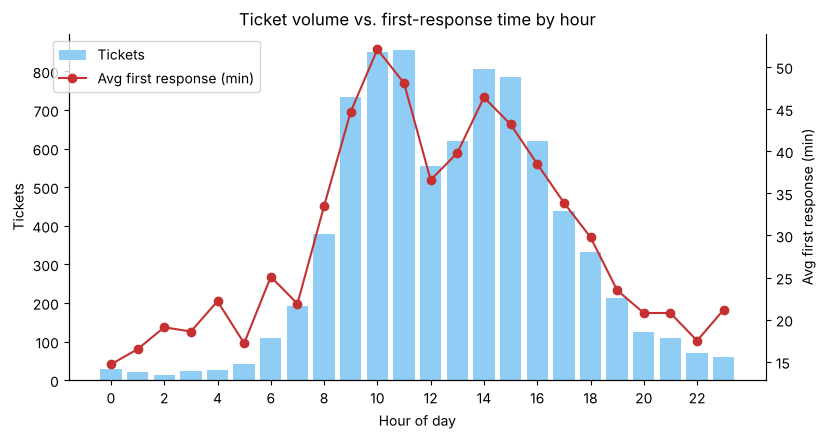

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
hr,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
tickets,29.0,21.0,12.0,23.0,26.0,42.0,110.0,192.0,378.0,733.0,850.0,855.0,556.0,619.0,806.0,785.0,620.0,437.0,331.0,213.0,125.0,109.0,69.0,59.0
avg_first_response_min,14.7,16.5,19.1,18.6,22.2,17.2,25.1,21.9,33.5,44.7,52.1,48.1,36.6,39.8,46.4,43.2,38.5,33.9,29.8,23.5,20.8,20.8,17.5,21.2


In [5]:
by_hour = q("""
SELECT hr,
       COUNT(*)                AS tickets,
       ROUND(AVG(frt_min), 1)  AS avg_first_response_min
FROM t
GROUP BY hr
ORDER BY hr
""")

fig, ax1 = plt.subplots()
ax1.bar(by_hour["hr"], by_hour["tickets"], color="#90cdf4", label="Tickets")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Tickets")
ax1.set_xticks(range(0, 24, 2))
ax2 = ax1.twinx()
ax2.plot(by_hour["hr"], by_hour["avg_first_response_min"], color="#c53030", marker="o", label="Avg first response (min)")
ax2.set_ylabel("Avg first response (min)")
ax2.spines["right"].set_visible(True)
ax1.set_title("Ticket volume vs. first-response time by hour")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.88))
plt.show()
by_hour.T

## 6. Volume by day of week

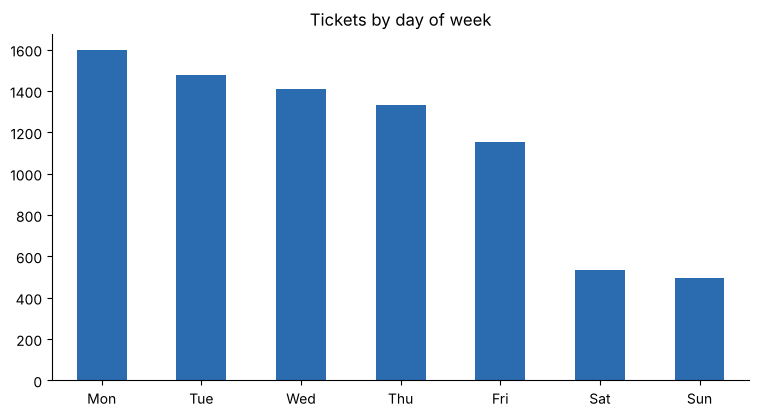

,tickets,avg_first_response_min
day,,
Mon,1596,40.5
Tue,1476,41.1
Wed,1411,37.7
Thu,1331,40.7
Fri,1152,38.7
Sat,536,38.1
Sun,498,40.5


In [6]:
names = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
by_dow = q("""
SELECT dow, COUNT(*) AS tickets, ROUND(AVG(frt_min), 1) AS avg_first_response_min
FROM t GROUP BY dow
""")
by_dow["day"] = by_dow["dow"].map(dict(enumerate(names)))
by_dow = by_dow.set_index("day").loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]].drop(columns="dow")

ax = by_dow["tickets"].plot.bar(color="#2b6cb0")
ax.set_title("Tickets by day of week")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.show()
by_dow

## 7. Busiest times: day x hour heatmap

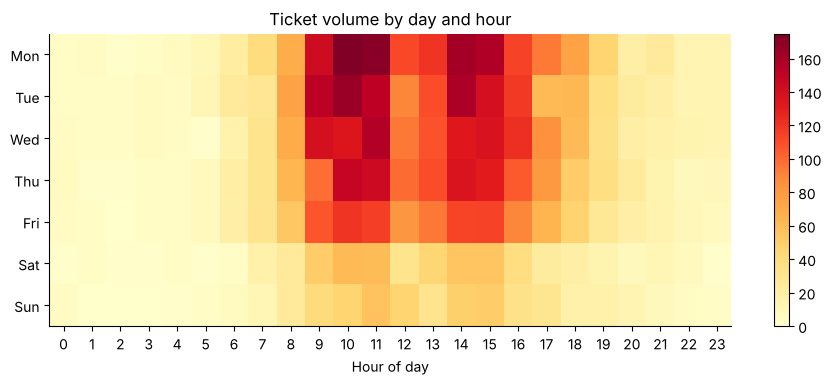

In [7]:
grid = q("SELECT dow, hr, COUNT(*) AS tickets FROM t GROUP BY dow, hr")
grid["day"] = grid["dow"].map(dict(enumerate(names)))
heat = (grid.pivot(index="day", columns="hr", values="tickets")
            .reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
            .reindex(columns=range(24)).fillna(0))

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(24), range(24))
ax.set_yticks(range(7), heat.index)
ax.set_xlabel("Hour of day")
ax.set_title("Ticket volume by day and hour")
fig.colorbar(im, ax=ax)
plt.show()

## 8. Which channels and categories are slowest?

In [8]:
by_channel = q("""
SELECT channel, COUNT(*) AS tickets,
       ROUND(AVG(frt_min), 1) AS avg_first_response_min,
       ROUND(AVG(res_hours), 1) AS avg_resolution_hours
FROM t GROUP BY channel ORDER BY avg_first_response_min DESC
""")
by_category = q("""
SELECT category, COUNT(*) AS tickets,
       ROUND(AVG(res_hours), 1) AS avg_resolution_hours
FROM t GROUP BY category ORDER BY avg_resolution_hours DESC
""")
print(by_channel.to_string(index=False))
print()
print(by_category.to_string(index=False))

 channel  tickets  avg_first_response_min  avg_resolution_hours
   Email     3006                    67.8                  14.8
Web form     1686                    50.4                  14.6
    Chat     2142                     9.8                  14.1
   Phone     1166                     6.8                  14.0

 category  tickets  avg_resolution_hours
 Delivery     1600                  25.9
Technical     2413                  19.0
  Billing     1557                   8.4
  Account     1212                   7.1
  General     1218                   5.7


## 9. Findings and recommendations (generated from the data)

In [9]:
top_hours = by_hour.sort_values("tickets", ascending=False).head(3)["hr"].tolist()
busiest_day = by_dow["tickets"].idxmax()
quietest_day = by_dow["tickets"].idxmin()
slow_hours = by_hour[by_hour["tickets"] >= 50].sort_values("avg_first_response_min", ascending=False).head(3)["hr"].tolist()
slowest_channel = by_channel.iloc[0]["channel"]
slowest_category = by_category.iloc[0]["category"]
weekday_share = round(100 * by_dow.loc[["Mon", "Tue", "Wed", "Thu", "Fri"], "tickets"].sum() / by_dow["tickets"].sum(), 1)

print(f"1. Peak hours: {', '.join(f'{h}:00' for h in top_hours)}  ->  schedule more agents at these times.")
print(f"2. Busiest day: {busiest_day}; quietest day: {quietest_day}  ->  weekday staffing should not be flat.")
print(f"3. {weekday_share}% of tickets arrive Mon-Fri.")
print(f"4. Slowest first responses (busy hours): {', '.join(f'{h}:00' for h in slow_hours)}  ->  response time rises when volume is high.")
print(f"5. Slowest channel for first response: {slowest_channel}; slowest category to resolve: {slowest_category}.")

1. Peak hours: 11:00, 10:00, 14:00  ->  schedule more agents at these times.
2. Busiest day: Mon; quietest day: Sun  ->  weekday staffing should not be flat.
3. 87.1% of tickets arrive Mon-Fri.
4. Slowest first responses (busy hours): 10:00, 11:00, 14:00  ->  response time rises when volume is high.
5. Slowest channel for first response: Email; slowest category to resolve: Delivery.


## 10. Export for Tableau

In [10]:
export = q("""
SELECT ticket_id, channel, category, created_at, hr AS hour_of_day, dow AS day_of_week_num,
       frt_min AS first_response_minutes, res_hours AS resolution_hours
FROM t
""")
export["day_of_week"] = export["day_of_week_num"].map(dict(enumerate(names)))
export.to_csv("output/tableau_support_tickets.csv", index=False)
by_hour.to_csv("output/volume_by_hour.csv", index=False)
print(sorted(os.listdir("output")))

['tableau_support_tickets.csv', 'volume_by_hour.csv']


## 11. Build the dashboard in Tableau
1. **Connect > Text file** and open `output/tableau_support_tickets.csv`.
2. Create a calculated field to order days: `Day Order = DATEPART('weekday', DATE([created_at]))` (or sort `day_of_week` manually Mon-Sun).
3. Sheets to build:
   - **Volume by hour:** `hour_of_day` on Columns, `COUNT(ticket_id)` on Rows.
   - **First response by hour:** `hour_of_day` on Columns, `AVG(first_response_minutes)` on Rows (dual axis with volume).
   - **Heatmap:** `hour_of_day` on Columns, `day_of_week` on Rows, `COUNT(ticket_id)` on Color.
   - **Channel and category:** bar charts of average first-response and resolution time.
4. Combine the sheets on one dashboard and add filters for `channel` and `category`, so non-technical users can explore.
5. Publish to Tableau Public and add the link and a screenshot to the README.